In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
from tqdm import tqdm
from scipy.signal import correlate
from scipy.stats import multivariate_normal
import os
import sys

import matplotlib

import plotly.graph_objects as go

from scipy.ndimage import gaussian_filter

module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from GLOBAL.ground_truths import *
from GLOBAL.torque import *
from GLOBAL.filters import *

#max_angle = 1000000 * np.pi / 180

with np.load("../GLOBAL/data.npz") as data:
    x_data=data['x_data']
    y_data=data['y_data']

n_trajectories = 2
x_data = x_data[:n_trajectories, :]
y_data = y_data[:n_trajectories, :]

def resample_spline(mean, cov):
    mean_resampled = np.repeat(mean, 2)
    diag_cov = np.diag(cov)
    diag_cov = np.repeat(diag_cov, 2)
    cov_resampled = np.diag(diag_cov)
    return mean_resampled, cov_resampled

Loading satellites/
Aspect ratio:  5
Ratio of rotational diffusion:  0.06769699908603415
Ratio of orthogonal diffusion:  0.7664558871581453


# Find proposal

In [2]:
def plot_torques(MEANS, COVS, n_knots=None, n_samples=10000, n_phis = 200, n_examples=0, torque_scale=50):
    #plt.figure(figsize=(4, 4))

    #MEANS = [m[1:] for m in MEANS]
    #COVS = [c[1:,1:] for c in COVS]
    
    phi = np.linspace(-np.pi * 0.1, 2.1 * np.pi, n_phis)
    phi_draw = phi * 180 / np.pi

    use = -1
    sample_mean = np.mean(MEANS[use:], axis=0)
    sample_cov = np.mean(np.array(COVS[use:]), axis=0)

    TORQUES = []

    SAMPLES = np.random.multivariate_normal(sample_mean, sample_cov, n_samples)


    for s in SAMPLES:
        TORQUES.append(TORQUE_FILTER(phi, s))

    TORQUES = np.array(TORQUES)

    Tmax = torque_scale
    Tmin = -torque_scale

    bins = np.linspace(Tmin, Tmax, n_phis)

    extent = [phi_draw.min(), phi_draw.max(), Tmin, Tmax]
    def hist1d(x):
        hist = np.histogram(x, bins=bins, density=True)[0]
        return hist / hist.max()

    density = np.apply_along_axis(hist1d, axis=0, arr=TORQUES, )

    density_ = gaussian_filter(density, (0.0,0))
    #plt.figure(dpi=300)
    cmap = matplotlib.colors.LinearSegmentedColormap.from_list("", ["white","yellowgreen"])
    plt.imshow(density_, extent=extent, aspect='auto', origin='lower', cmap=cmap)

    torque_mean = np.mean(TORQUES, axis=0)
    torque_mode = bins[np.argmax(density_, axis=0)]
    torque_std = np.std(TORQUES, axis=0)

    torque_true = TORQUE(phi, ALPHAS)

    #if n_knots is not None:
    #    phi_knots = np.linspace(0, np.pi, n_knots+2)[1:-1]
    #    torque_knots = TORQUE(phi_knots, ALPHAS)
    #
    #    plt.scatter(phi_knots, torque_knots, c='r', s=10)
    #    #for phi_ in phi_knots:
    #    #    plt.axvline(phi_, color='k', alpha=0.5, lw=0.5, ls='--')

    
    for i in range(n_examples):

        SAMPLES = np.random.multivariate_normal(sample_mean, sample_cov, 1)

        TORQUES = []
        for s in SAMPLES:
            TORQUES.append(TORQUE_FILTER(phi, s))
        
        plt.plot(phi_draw, TORQUES[0], lw=1, alpha=1, ls='--', c='darkgreen')

    col='olivedrab'
    qtil = 2.575829
    
    plt.plot(phi_draw, torque_mean - qtil*torque_std, ':', lw=0.7, c=col)
    plt.plot(phi_draw, torque_mean + qtil*torque_std, ':', lw=0.7, c=col)
    #plt.plot(phi, torque_mode, '--', lw=0.7, alpha=1, c=col)
    #plt.plot(phi, torque_true, '-', lw=2, alpha=1, c='r')
    plt.axvline(0, color='k', lw=2)
    plt.axvline(360, color='k', lw=2)
    plt.grid()
    plt.ylim(Tmin, Tmax)
    plt.xticks(np.arange(0, 360+1, 90))

    

In [3]:
def plot_cov_ellipse(mean, cov, color='b'):
    phi = np.linspace(0, 2*np.pi, 100)
    chol = np.linalg.cholesky(cov[:2, :2])
    ellipse = np.array([np.cos(phi), np.sin(phi)])
    plt.plot(*(chol@ellipse + mean[:2][:, None]), c=color)
    ellipse = 2*np.array([np.cos(phi), np.sin(phi)])
    plt.plot(*(chol@ellipse + mean[:2][:, None]), c=color, ls='--')

In [4]:
d0 = 0
d1 = 1

ndims = 4
centers = np.zeros(ndims)
count = 0

In [5]:
def learn(progression=range(20),
          sample_count=1024 // 64,
          torque_scale=200,
          new_samples_only=True,
          max_angle = 90 * np.pi / 180,
          particle_count=100,
          clip_parameters=1000,
          mixing_ratio=0.8,
          search_size=1,
          smoothing_factor=1.0):
    global mean, cov, ALL_COORDS, ALL_TARGET_DENSITIES, ALL_LIKELIHOODS, count
    for prog in tqdm(progression):

        ''' GENERATE NEW TEST SAMPLES '''

        distribution = multivariate_normal(mean=mean, cov=search_size*cov, allow_singular=False)
        coords = distribution.rvs(sample_count)
        likelihood = distribution.pdf(coords)

        ''' EVALUATE POSTERIOR AT TEST POINTS '''

        logl, _, _ = calc_logl_core(x_data, y_data, dt,
                                    PE, DT, DR, FORCE_STRENGTH,
                                    coords, torque_limit=max_angle,
                                    n_particles=particle_count,
                                    clip_parameters=clip_parameters,
                                    )
        logl = logl - np.max(logl)
        target_density = np.exp(logl / smoothing_factor)
        #target_density = target_density / np.sum(target_density)

        # (Remnant of old testing code. More stable but incorrect.)
        ALL_COORDS = np.concatenate((ALL_COORDS, coords))
        ALL_TARGET_DENSITIES = np.concatenate((ALL_TARGET_DENSITIES, target_density))
        ALL_LIKELIHOODS = np.concatenate((ALL_LIKELIHOODS, likelihood))
        #ALL_LIKELIHOODS = distribution.pdf(ALL_COORDS)

        # (Delete old data, otherwise the fit isn't correct -> Mitigating above issue.)
        if new_samples_only:
            ALL_COORDS = coords
            ALL_TARGET_DENSITIES = target_density
            ALL_LIKELIHOODS = likelihood

        ''' CALULATE NEW MEAN AND COVARIANCE'''
        mean_old = mean
        cov_old = cov
        mean = np.average(ALL_COORDS, axis=0, weights=ALL_TARGET_DENSITIES/ALL_LIKELIHOODS)
        cov = np.cov(ALL_COORDS.T, aweights=ALL_TARGET_DENSITIES/ALL_LIKELIHOODS)

        #cov /= smoothing_factor**2

        if np.any(np.isnan(cov)):
            cov = cov_old

        # (Stabilize the fit by mixing the old and new parameters)
        mixing_ratio = mixing_ratio
        mean = mixing_ratio * mean + (1 - mixing_ratio) * mean_old
        cov = mixing_ratio * cov + (1 - mixing_ratio) * cov_old

        ''' STORE PROGRESS '''

        COVS.append(cov.copy())
        MEANS.append(mean.copy())

        plt.figure(dpi=120, figsize=(5, 5))

        ''' PLOT ORIGINAL LOG PARAMETERS '''

        plt.subplot(2, 2, 1)
        plt.gca().set_facecolor('silver')
        #chan = np.exp(ALL_TARGET_DENSITIES/10)
        chan = logl
        plt.hexbin((ALL_COORDS)[:, d0], (ALL_COORDS)[:, d1], C=chan, gridsize=32, reduce_C_function=np.max)
        plt.axvline(centers[0], color='r', linestyle='--', lw=1)
        plt.axhline(centers[1], color='r', linestyle='--', lw=1)
        plot_cov_ellipse(mean, cov, color='w')

        ''' PLOT ROTATED PARAMETERS '''

        eivals, eivecs = np.linalg.eig(cov)
        idx = np.argsort(np.abs(eivals))[::-1]
        eivals = eivals[idx]
        eivecs = eivecs[:, idx]
        def rotate(vec):
            return np.dot(vec, eivecs)
        
        def rotate_mat(mat):
            return np.dot(np.dot(eivecs.T, mat), eivecs)
        
        plt.subplot(2, 2, 2)
        plt.gca().set_facecolor('silver')
        #chan = np.exp(ALL_TARGET_DENSITIES/10)
        chan = logl
        plt.hexbin(rotate(ALL_COORDS)[:, d0], rotate(ALL_COORDS)[:, d1], C=chan, gridsize=32)
        plot_cov_ellipse(rotate(mean), rotate_mat(cov), color='w')


        ''' PLOT CONVERGENCE '''

        plt.subplot(2, 2, 3)

        COVS_flat = [cov_.copy() for cov_ in COVS]
        for cov_ in COVS_flat:
            np.fill_diagonal(cov_, np.nan)
        COVS_flat = [cov_.flatten() for cov_ in COVS]

        COVS_flat = np.stack(COVS_flat, axis=0)
        plt.semilogy(np.abs(COVS_flat), 'red', label='Covariances')

        COVS_flat = [np.diagonal(cov) for cov in COVS]
        COVS_flat = np.stack(COVS_flat, axis=0)
        plt.semilogy(np.abs(COVS_flat), 'blue', label='Diagonals')
        plt.xlabel("Iteration")
        plt.ylabel("Covariance matrix element")

        ''' PLOT POSTERIOR TORQUE '''

        plt.subplot(2, 2, 4)
        plot_torques(MEANS, COVS, n_knots=ndims-1, torque_scale=torque_scale)
        plt.tight_layout()
        plt.savefig(f"img/proposal_convergence{count}.png", dpi=300)
        plt.show()
        count += 1

# Learning

## Initial Run

In [19]:
# Set up base run

n_trajectories = 10
x_data = x_data[:n_trajectories, :]
y_data = y_data[:n_trajectories, :]

clipping = np.inf

search_size = 2
initial_radius = 400
ndims = 3
centers = np.zeros(ndims)
mean = centers.copy()
cov = np.eye(ndims) * initial_radius**2

COVS = [cov.copy()]
MEANS = [mean.copy()]

count = 0

ALL_COORDS = np.zeros((0, ndims))
ALL_TARGET_DENSITIES = np.zeros(0)
ALL_LIKELIHOODS = np.zeros(0)

COVS = [cov.copy()]
MEANS = [mean.copy()]

learn(progression=range(40),
      sample_count=1024//1,
      particle_count=4000,
      new_samples_only=True,
      torque_scale=initial_radius,
      clip_parameters=clipping,
      search_size=search_size,
      mixing_ratio=0.97,
      smoothing_factor=1.,
      max_angle = 10 * np.pi / 180,
      )

mean_1 = mean.copy()
cov_1 = cov.copy()

np.save("mean_1.npy", mean_1)
np.save("cov_1.npy", cov_1)

  0%|                                       | 0/40 [00:04<?, ?it/s]


KeyboardInterrupt: 

# Refinement 1 Prepare Run

  0%|                                       | 0/40 [00:00<?, ?it/s]

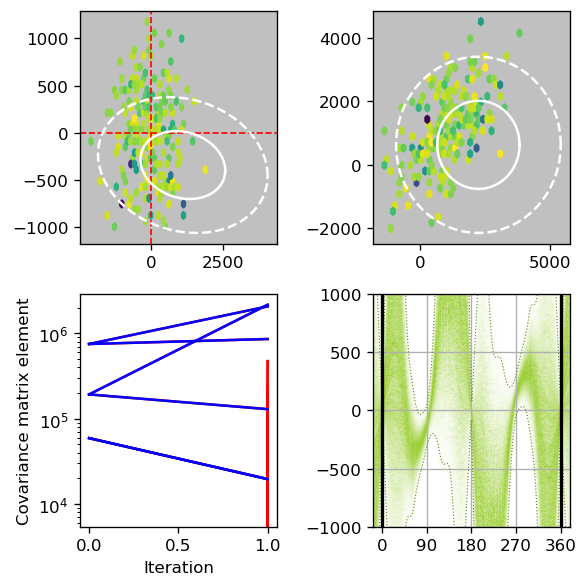

  2%|▋                           | 1/40 [02:22<1:32:44, 142.67s/it]

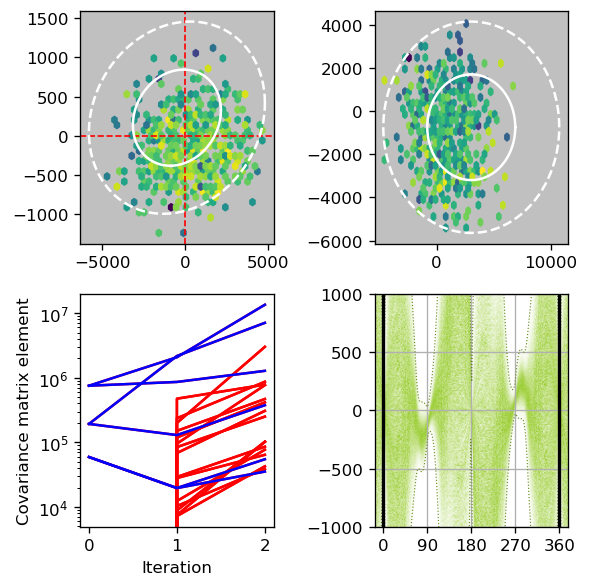

  5%|█▍                          | 2/40 [04:28<1:24:06, 132.80s/it]

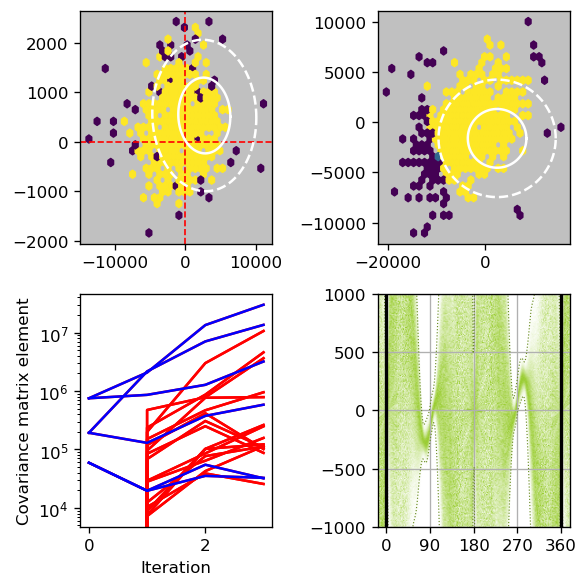

  8%|██                          | 3/40 [06:27<1:18:00, 126.51s/it]

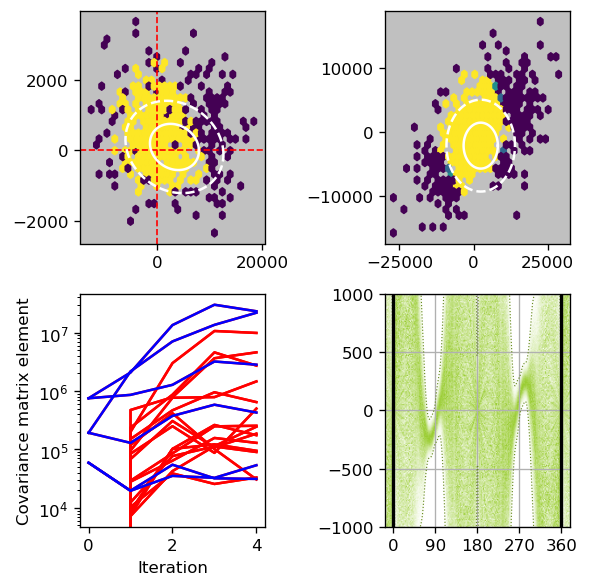

 10%|██▊                         | 4/40 [08:03<1:08:40, 114.45s/it]

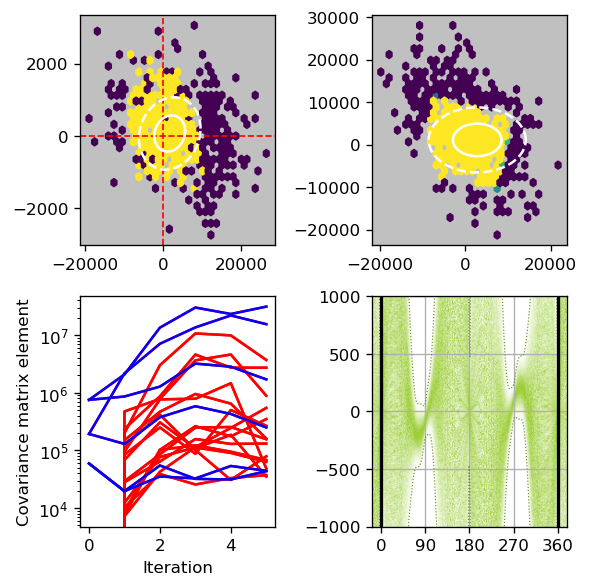

 12%|███▌                        | 5/40 [09:36<1:02:20, 106.87s/it]

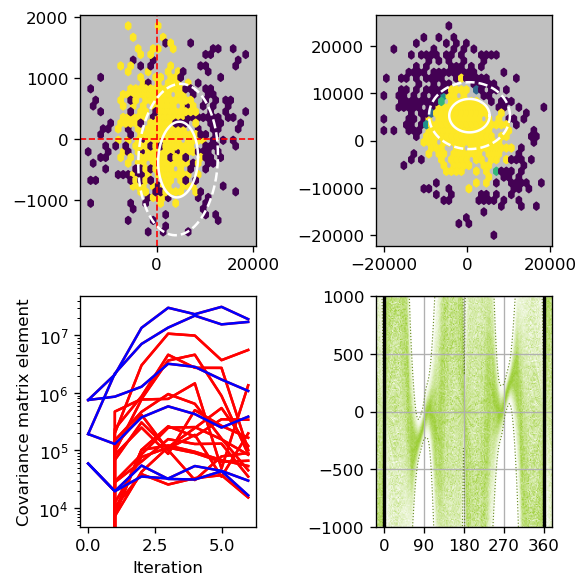

 15%|████▌                         | 6/40 [11:13<58:31, 103.29s/it]

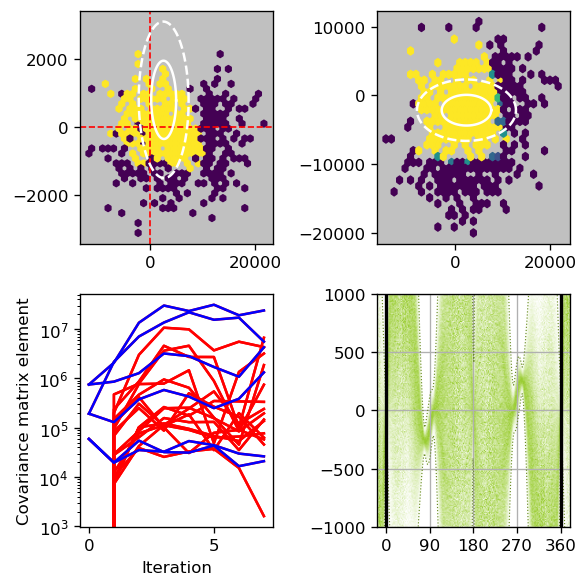

 18%|█████▍                         | 7/40 [12:45<54:44, 99.52s/it]

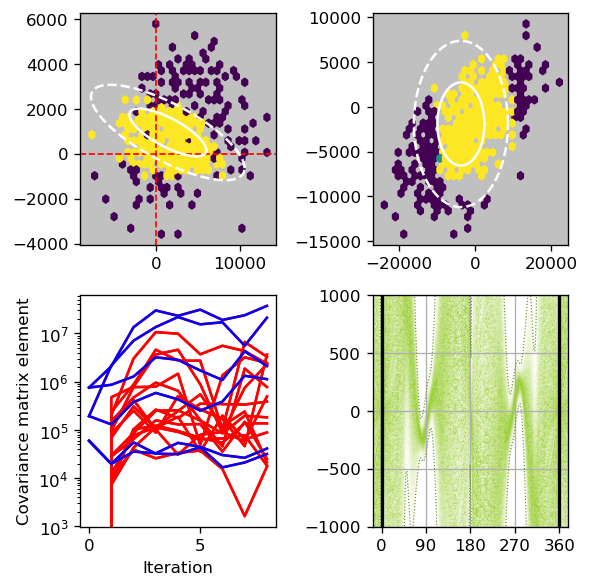

 20%|██████                        | 8/40 [14:33<54:36, 102.40s/it]

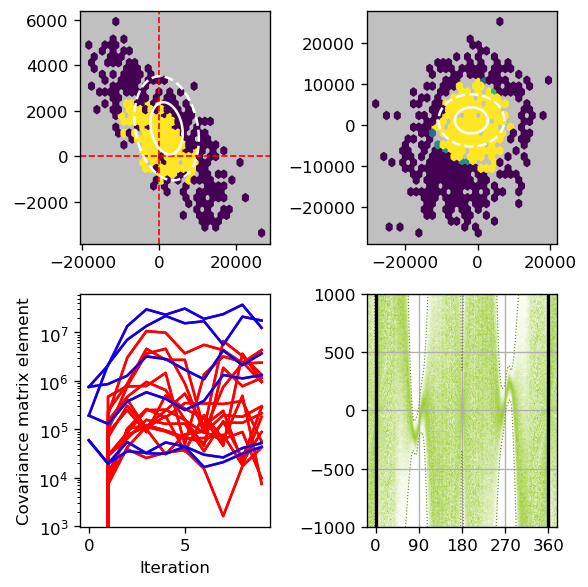

 22%|██████▉                        | 9/40 [15:53<49:20, 95.50s/it]

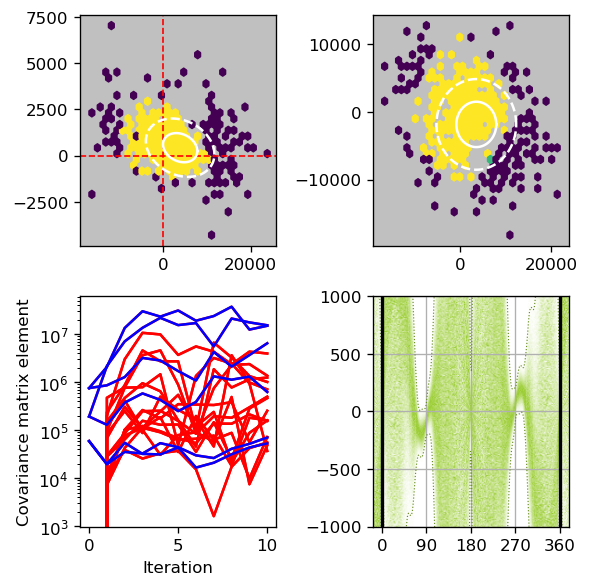

 25%|███████▎                     | 10/40 [17:44<50:05, 100.17s/it]

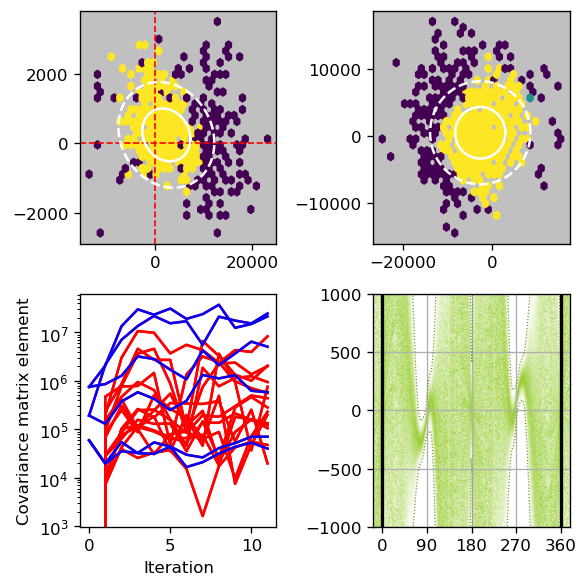

 28%|███████▉                     | 11/40 [19:25<48:35, 100.52s/it]

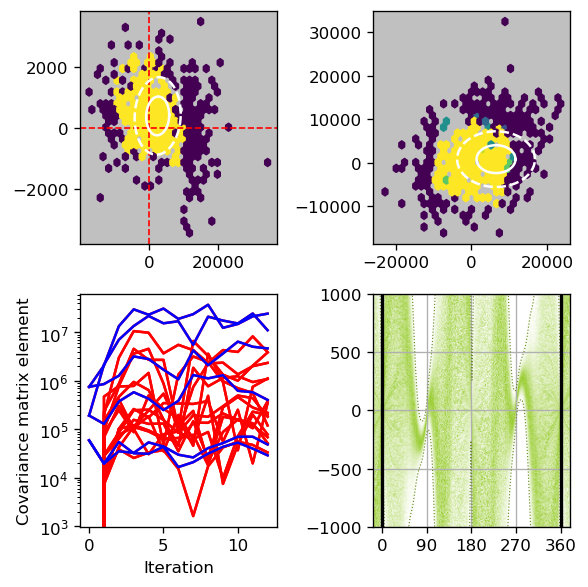

 30%|█████████                     | 12/40 [20:59<45:56, 98.46s/it]

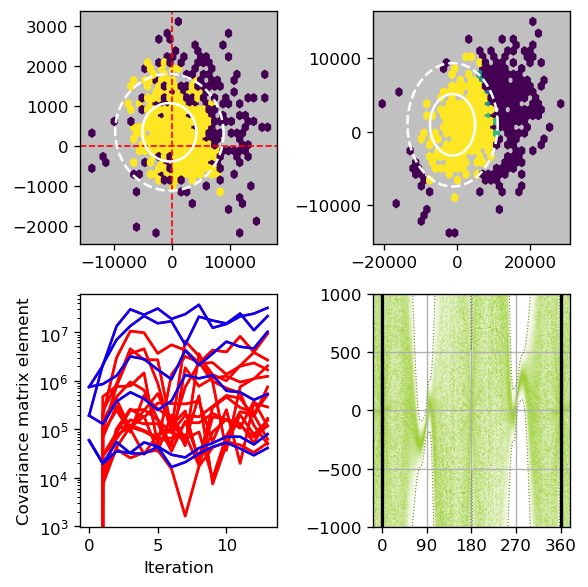

 32%|█████████▍                   | 13/40 [23:03<47:41, 106.00s/it]

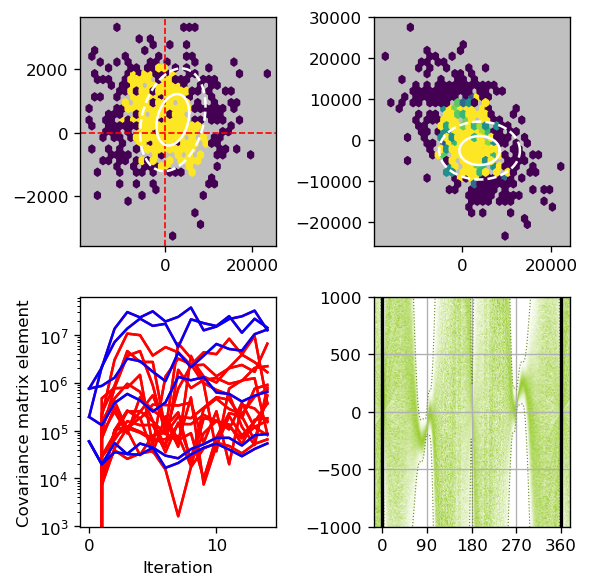

 35%|██████████▏                  | 14/40 [24:33<43:50, 101.17s/it]

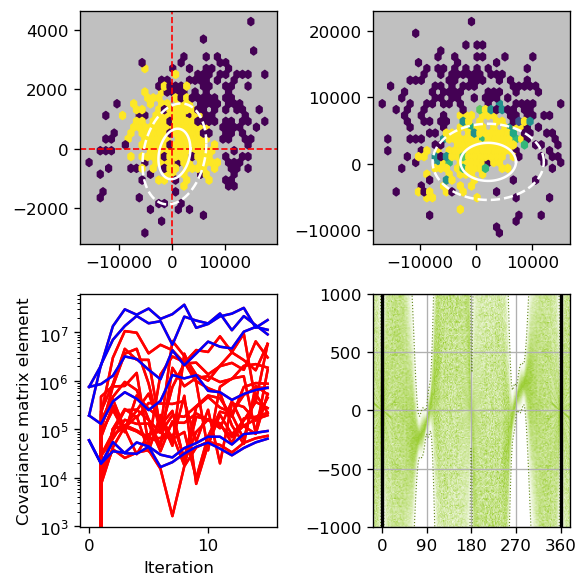

 38%|██████████▉                  | 15/40 [26:14<42:08, 101.15s/it]

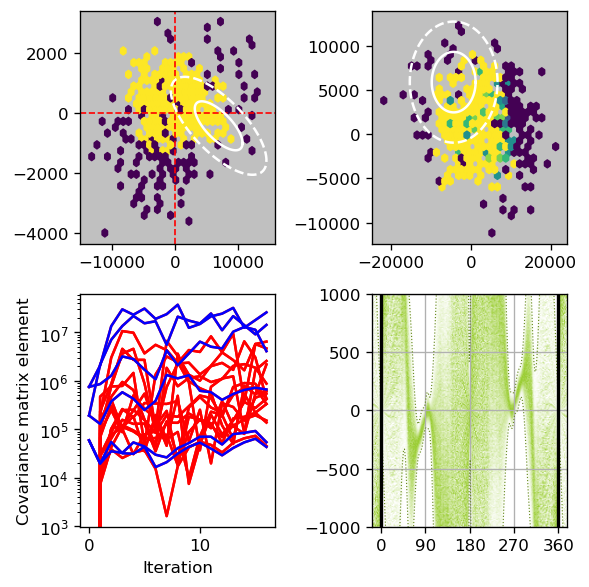

 40%|███████████▌                 | 16/40 [28:01<41:12, 103.02s/it]

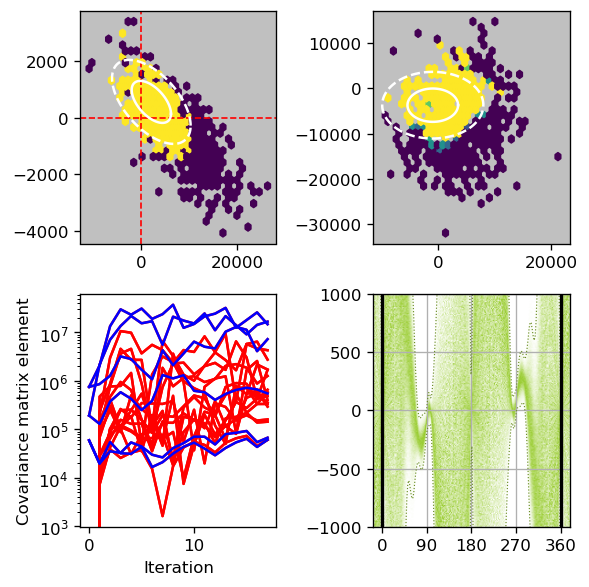

 42%|████████████▊                 | 17/40 [29:25<37:19, 97.39s/it]

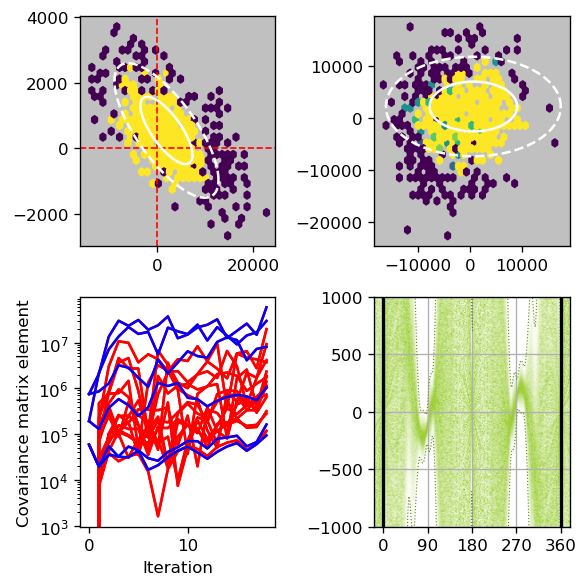

 45%|█████████████▌                | 18/40 [31:09<36:25, 99.36s/it]

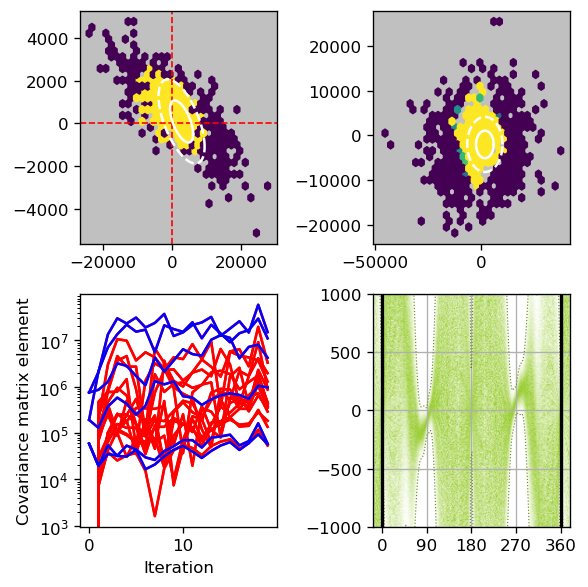

 48%|██████████████▎               | 19/40 [32:23<32:03, 91.61s/it]

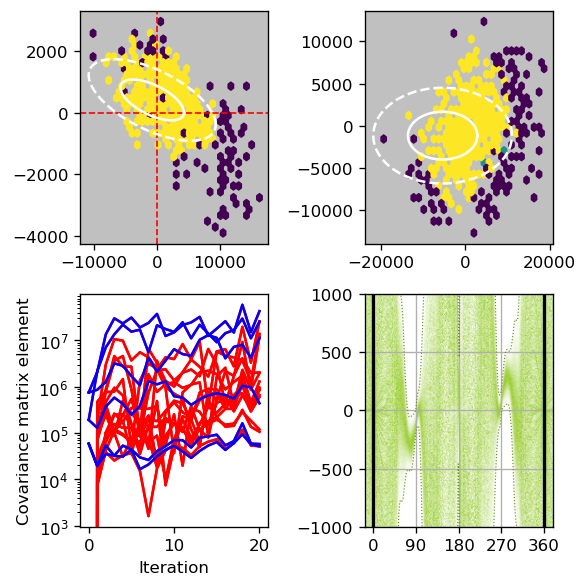

 50%|███████████████               | 20/40 [34:16<32:41, 98.09s/it]

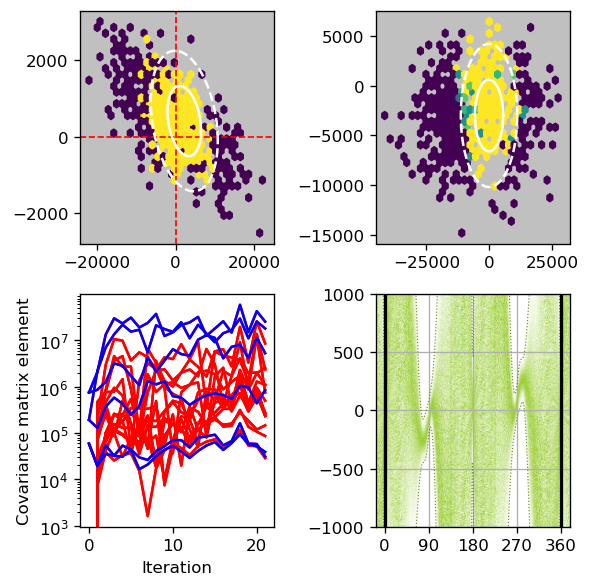

 52%|███████████████▊              | 21/40 [35:37<29:23, 92.84s/it]

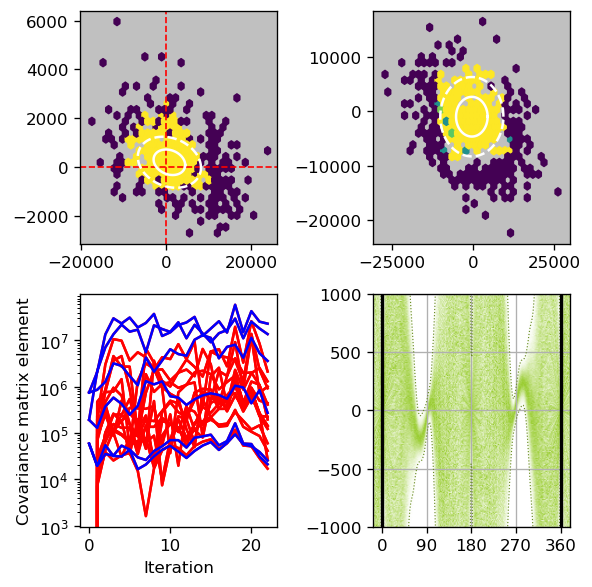

 55%|████████████████▌             | 22/40 [37:11<28:00, 93.35s/it]

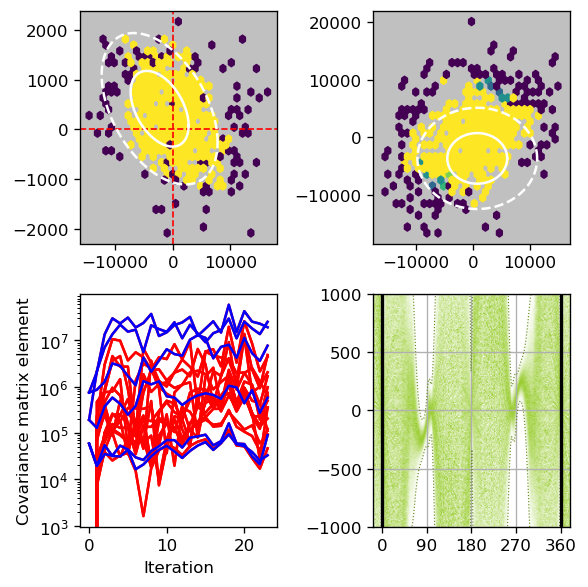

 57%|█████████████████▎            | 23/40 [38:59<27:41, 97.71s/it]

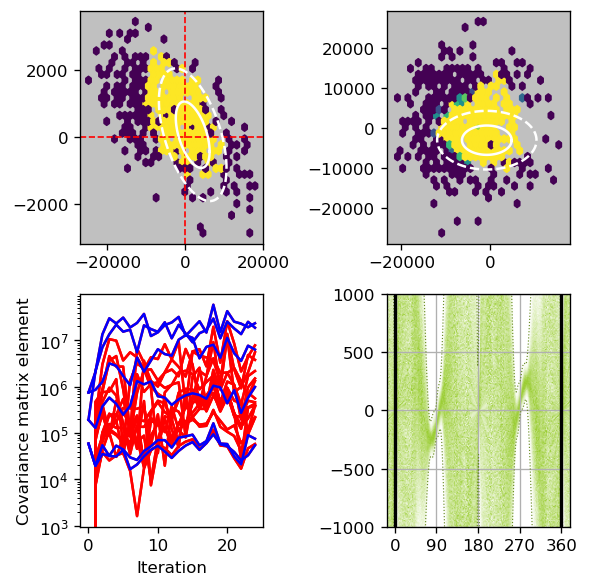

 60%|██████████████████            | 24/40 [40:28<25:22, 95.13s/it]

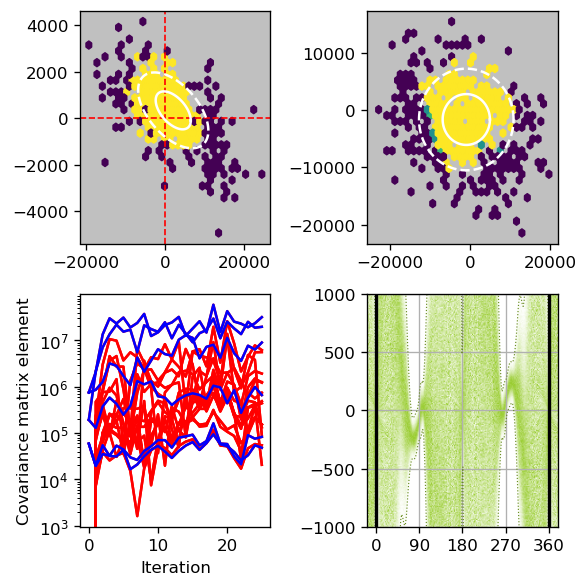

 62%|██████████████████▊           | 25/40 [42:06<24:00, 96.06s/it]

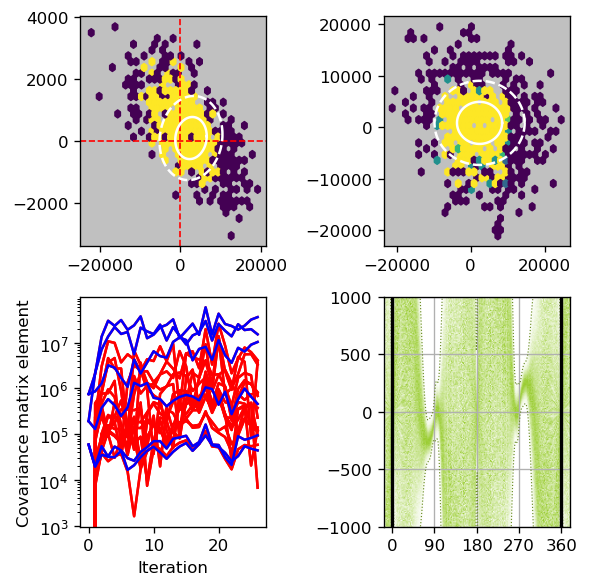

 65%|███████████████████▌          | 26/40 [43:31<21:36, 92.64s/it]

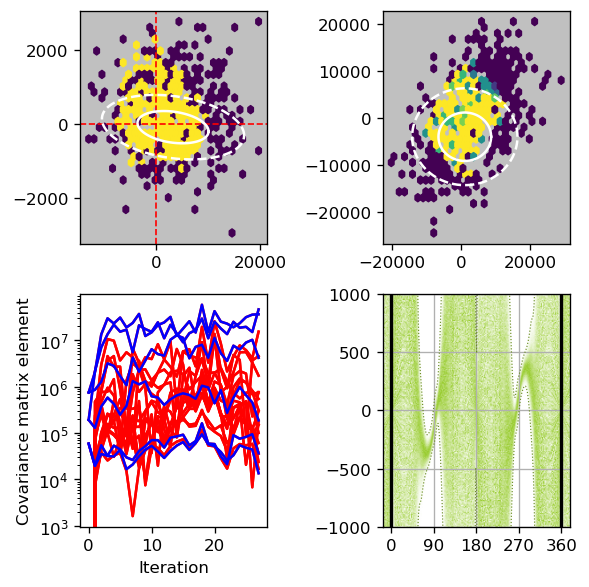

 68%|████████████████████▎         | 27/40 [44:57<19:37, 90.54s/it]

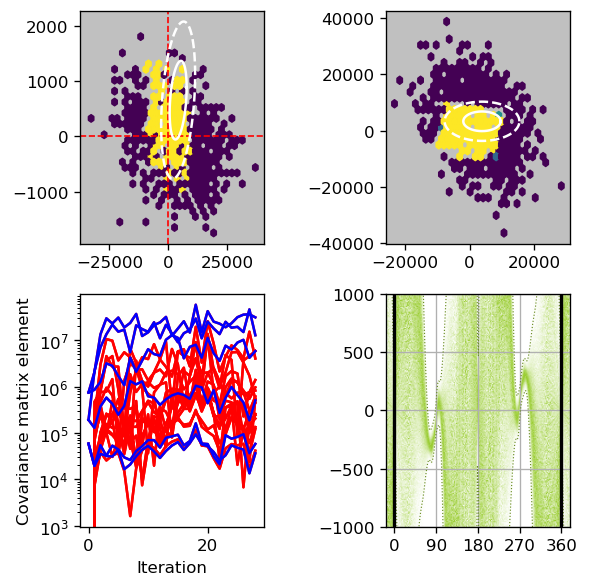

 70%|█████████████████████         | 28/40 [46:06<16:48, 84.05s/it]

In [ ]:
# Refinement of the torque function

mean_1 = np.load("mean_1.npy")
cov_1 = np.load("cov_1.npy")

n_trajectories = 18
x_data = x_data[:n_trajectories, :]
y_data = y_data[:n_trajectories, :]

#search_size = 4
ndims = 6
mean, cov = resample_spline(mean_1, cov_1)
#mean, cov = mean_1, cov_1

COVS = [cov.copy()]
MEANS = [mean.copy()]

count = 0

ALL_COORDS = np.zeros((0, ndims))
ALL_TARGET_DENSITIES = np.zeros(0)
ALL_LIKELIHOODS = np.zeros(0)

COVS = [cov.copy()]
MEANS = [mean.copy()]

clipping = 10000

learn(progression=range(40),
      sample_count=1024//1,
      particle_count=4000,
      new_samples_only=True,
      torque_scale=1000,
      clip_parameters=clipping,
      search_size=search_size,
      mixing_ratio=0.97,
      smoothing_factor=1.,
      max_angle = 10 * np.pi / 180,
      )


cov_2 = cov.copy()
mean_2 = mean.copy()

np.save("mean_2.npy", mean_2)
np.save("cov_2.npy", cov_2)
